# risque de crédit d'un portefeuille

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

Partie 1 : le portefeuille et sa perte attendue ( 200 préts à 200 milliard d'euro)

In [79]:
rng = np.random.default_rng(42)  #meme tirage à chaque excécution
n = 200
ratings = rng.choice(["BBB", "BB", "B"], size=n, p=[0.3, 0.4, 0.3]) #tire 200 ratings au hasard, avec 30 % de chances d’obtenir BBB, 40 % BB et 30 % B. Tu obtiens donc environ 60 prêts BBB, 80 prêts BB et 60 prêts B. Les trois valeurs de p doivent faire 1 au total.

In [80]:
pd_par_rating ={"BBB": 0.002, "BB": 0.01, "B": 0.039}
pd_par_rating

{'BBB': 0.002, 'BB': 0.01, 'B': 0.039}

In [81]:
#portofolio=port
#EAD tiré un nbre  aléatoirement par rng de 5 à 15 sur 200 pret 
Port=pd.DataFrame({"Rating":ratings,"pd_par_rating":pd.Series(ratings).map(pd_par_rating),"EAD":rng.uniform(5,15,n),"LGD":0.45})
Port

,Rating,pd_par_rating,EAD,LGD
0,B,0.039,12.774048,0.45
1,BB,0.010,14.718264,0.45
2,B,0.039,10.007412,0.45
3,BB,0.010,6.438975,0.45
4,BBB,0.002,5.139363,0.45
...,...,...,...,...
195,BBB,0.002,9.543180,0.45
196,BB,0.010,13.253995,0.45
197,B,0.039,7.953590,0.45
198,BBB,0.002,9.585481,0.45


In [82]:
Port["EL"]=Port["EAD"]*Port["pd_par_rating"]*Port["LGD"]
Port.head()

,Rating,pd_par_rating,EAD,LGD,EL
0,B,0.039,12.774048,0.45,0.224185
1,BB,0.010,14.718264,0.45,0.066232
2,B,0.039,10.007412,0.45,0.175630
3,BB,0.010,6.438975,0.45,0.028975
4,BBB,0.002,5.139363,0.45,0.004625


In [83]:
#resume
Pd_Moyen=Port["pd_par_rating"].mean()
print (Pd_Moyen)
EAD_Total=Port["EAD"].sum()
print (EAD_Total)
EL_Total=Port["EL"].sum()

print (EL_Total)
print(f"Exposition totale : {EAD_Total:,.0f} M€")
print(f"Perte attendue : {EL_Total:.1f} M€, soit {EL_Total / EAD_Total:.2%} du portefeuille")


0.016010000000000003
1998.4463538509112
14.355863065615889
Exposition totale : 1,998 M€
Perte attendue : 14.4 M€, soit 0.72% du portefeuille


In [84]:
#Dans .agg, chaque parenthèse se lit (colonne, opération) :le premier mot est la colonne du tableau à utiliser ;le second est l’opération à faire dessus : "sum", "mean", "size", "max"

resume = Port.groupby("Rating").agg(nb=("EAD", "size"), EAD=("EAD", "sum"),EL=("EL", "sum"))
resume["part_EAD"] = resume["EAD"] / EAD_Total
resume["part_EL"] = resume["EL"] / EL_Total
resume.round(3)

,nb,EAD,EL,part_EAD,part_EL
Rating,,,,,
B,58,574.517,10.083,0.287,0.702
BB,82,830.986,3.739,0.416,0.260
BBB,60,592.943,0.534,0.297,0.037


les prets B représente l'exposition la plus faible , et la plus grande perte attendue  
Explication : L’appétit pour le risque. La banque fixe des limites : elle prête moins, et des montants plus petits, aux emprunteurs risqués.
Le coût en capital. Tu le verras à la partie 5 : un prêt B consomme environ 4 fois plus de capital qu’un prêt BBB, avec des pondérations d’environ 120 % contre 30 %. Prêter beaucoup en B coûte donc très cher en fonds propres.
Les gros prêts vont aux grandes entreprises. Elles sont souvent bien notées (BBB et plus) et empruntent des montants importants. Les entreprises notées B sont souvent plus petites, ou sous LBO.
La distribution du risque. Les prêts B sous LBO sont souvent syndiqués : la banque n’en garde qu’une petite partie et revend le reste, par exemple à des CLO. C’est exactement la logique « originate-to-distribute » de PAM.

Partie 2 : simuler les pertes avec le modèle à un facteur ( Vasicek) 

Le modèle à facteur ne sert pas à calculer l’EL : on l’a déjà avec PD × LGD × EAD, sans aucune simulation. Il sert à obtenir toute la distribution des pertes, c’est-à-dire ce qui se passe les bonnes années, les années moyennes et les très mauvaises années.

L'idée du modèle
Chaque emprunteur i a une « santé » X, mélange d'un facteur commun Z (l'économie) et d'un choc propre ε (l'entreprise elle-même) :
Chaque emprunteur $i$ a une variable latente $X_i$, mélange d'un facteur commun $Z$ (l'économie) et d'un choc propre $\varepsilon_i$ :

$$X_i = \sqrt{\rho}\, Z + \sqrt{1-\rho}\, \varepsilon_i \qquad Z,\ \varepsilon_i \sim \mathcal{N}(0,1)$$

L'emprunteur fait défaut si sa variable passe sous un seuil fixé par sa PD :

$$\text{défaut}_i \iff X_i < \Phi^{-1}(PD_i)$$

où $\rho$ est la corrélation d'actifs et $\Phi^{-1}$ l'inverse de la fonction de répartition de la loi normale.

In [85]:
def simuler_pertes(Port, rho, n_sim=50000, graine=1):
    """Renvoie n_sim pertes annuelles simulées, en % du portefeuille."""
    rng = np.random.default_rng(graine)
    seuil = norm.ppf(Port["pd_par_rating"].values)                # un seuil par prêt
#norm.ppf est l’inverse de la fonction de répartition de la loi normale, noté Φ⁻¹ dans les formule
    Z = rng.standard_normal((n_sim, 1))                  # 1 facteur commun par scénario
    epsilon = rng.standard_normal((n_sim, len(Port)))    # 1 choc propre par prêt et par scénario
    X = np.sqrt(rho) * Z + np.sqrt(1 - rho) * epsilon

    defaut = X < seuil                                 #true/false 
          
    return defaut
defaut=simuler_pertes(Port,0.15,n_sim=50000,graine=1)
print(defaut)
tableau_defauts = pd.DataFrame( defaut,  index=[f"Année {i+1}" for i in range(defaut.shape[0])],columns=[f"Prêt {j} ({r})" for j, r in enumerate(Port["Rating"])])
tableau_defauts.iloc[:10, :8] 

[[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]


,Prêt 0 (B),Prêt 1 (BB),Prêt 2 (B),Prêt 3 (BB),Prêt 4 (BBB),Prêt 5 (B),Prêt 6 (B),Prêt 7 (B)
Année 1,False,False,False,False,False,False,False,False
Année 2,False,False,False,False,False,False,False,False
Année 3,False,False,False,False,False,False,False,False
Année 4,False,False,False,False,False,False,True,True
Année 5,False,False,False,False,False,False,False,False
Année 6,False,False,False,False,False,False,False,False
Année 7,False,False,False,False,False,False,False,False
Année 8,False,False,False,False,False,False,False,False
Année 9,False,False,False,False,False,False,False,False
Année 10,False,False,False,False,False,False,False,False


la plupart false car le défaut est rare since PD par rating Moyen est 0.016

In [86]:
perte_si_defaut = (Port["EAD"] * Port["LGD"]).values     #la part non recupéré
   
tableau_perte_si_defaut = pd.DataFrame({  "Rating": Port["Rating"],  "EAD": Port["EAD"], "Perte si défaut (M€)": perte_si_defaut,"part_perte":perte_si_defaut/Port["EAD"].sum()})
tableau_perte_si_defaut.head(8)

,Rating,EAD,Perte si défaut (M€),part_perte
0,B,12.774048,5.748322,0.002876
1,BB,14.718264,6.623219,0.003314
2,B,10.007412,4.503335,0.002253
3,BB,6.438975,2.897539,0.001450
4,BBB,5.139363,2.312713,0.001157
5,B,7.296560,3.283452,0.001643
6,B,6.318222,2.843200,0.001423
7,B,11.776587,5.299464,0.002652


In [87]:
def simuler_pertes(Port, rho, n_sim=50_000, graine=1):
    """Renvoie n_sim pertes annuelles simulées, en % du portefeuille."""
    rng = np.random.default_rng(graine)
    seuil = norm.ppf(Port["pd_par_rating"].values)                # un seuil par prêt

    Z = rng.standard_normal((n_sim, 1))                  # 1 facteur commun par scénario
    eps = rng.standard_normal((n_sim, len(Port)))        # 1 choc propre par prêt et par scénario
    X = np.sqrt(rho) * Z + np.sqrt(1 - rho) * eps

    defaut = X < seuil                                   # tableau de True / False
    perte_si_defaut = (Port["EAD"] * Port["LGD"]).values
    pertes = defaut @ perte_si_defaut                    # somme des pertes de chaque scénario
    return pertes / Port["EAD"].sum() * 100

In [88]:
pertes = simuler_pertes(Port, rho=0.15)
EL_simulé = pertes.mean()
VaR = np.quantile(pertes, 0.999)          # quantile 99,9 % : celui de Bâle
ES = pertes[pertes >= VaR].mean()         # moyenne des pertes au-delà de la VaR
UL = VaR - EL_simulé                     # perte inattendue

print(f"EL simulée : {EL_simulé:.2f} %  (théorique : {EL_Total / EAD_Total:.2%})")
print(f"VaR 99,9 % : {VaR:.2f} %")
print(f"ES 99,9 %  : {ES:.2f} %")
print(f"Perte inattendue : {UL:.2f} %, soit {UL / 100 * EAD_Total:.0f} M€")

EL simulée : 0.72 %  (théorique : 0.72%)
VaR 99,9 % : 6.46 %
ES 99,9 %  : 7.78 %
Perte inattendue : 5.74 %, soit 115 M€


L’UL mesure de combien une très mauvaise année dépasse une année normale. Elle est grande parce que la distribution des pertes de crédit est très asymétrique

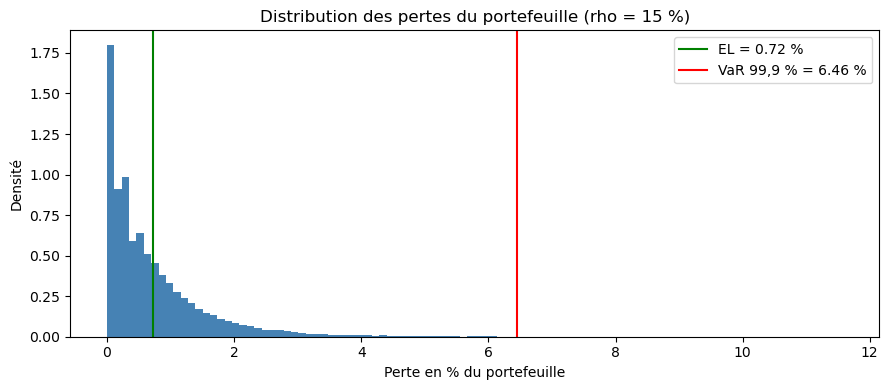

In [89]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(pertes, bins=100, density=True, color="steelblue")
ax.axvline(EL_simulé, color="green", label=f"EL = {EL_simulé:.2f} %")
ax.axvline(VaR, color="red", label=f"VaR 99,9 % = {VaR:.2f} %")
ax.set_title("Distribution des pertes du portefeuille (rho = 15 %)")
ax.set_xlabel("Perte en % du portefeuille")
ax.set_ylabel("Densité")
ax.legend()
plt.tight_layout()
plt.show()

le  graphique montre les 50 000 années simulées, rangées selon la perte de chaque année.

L’axe horizontal donne la perte d’une année, en % du portefeuille. Chaque barre regroupe les années dont la perte tombe dans un petit intervalle.

L’axe vertical (densité) indique combien d’années tombent dans chaque barre. Plus la barre est haute, plus ce niveau de perte est fréquent. On utilise la densité plutôt que le nombre d’années pour que la surface totale des barres fasse 1 : la surface d’une barre est alors la probabilité de tomber dans cet intervalle.

Pourquoi un pic en 0 ? Parce que la plupart des années sont calmes. Avec 200 prêts et une PD moyenne de 1,6 %, une année typique compte 0 à 3 défauts. Beaucoup d’années n’ont aucun défaut, donc une perte de 0 : c’est la grande barre à gauche. Les barres suivantes correspondent à 1 défaut, 2 défauts…

Les barres sont irrégulières près de 0 (haut, bas, haut) parce qu’un défaut ajoute environ 0,2 % de perte d’un coup : 1 prêt ≈ 4,5 M€ sur 2 000 M€. Les pertes avancent donc par paliers.

La lecture de gauche à droite :

Entre 0 et 1 % : la grande majorité des années. Rien de grave.
Entre 1 et 4 % : des années plus difficiles, de moins en moins fréquentes. Les barres descendent.
Au-delà de 4 % : les barres sont si basses qu’on ne les voit plus, mais elles existent. L’axe va jusqu’à 12 % parce qu’une année simulée a perdu environ 11,6 % : une récession extrême. C’est la queue de distribution, invisible ici mais décisive pour le capital. À la partie 3, l’échelle logarithmique la rendra visible.

Comment lire l’EL (trait vert, 0,72 %)

C’est la perte moyenne sur toutes les années. Sur la durée, la banque perd en moyenne 0,72 % du portefeuille par an, soit environ 14 M€.

Remarque que l’EL est à droite du pic : la plupart des années perdent moins que l’EL. La moyenne est tirée vers le haut par les quelques années très mauvaises de la queue. C’est le signe d’une distribution asymétrique.

La banque prévoit cette perte : elle la couvre par la marge sur les prêts et par les provisions.

Comment lire la VaR à 99,9 % (trait rouge, 6,46 %)

C’est la perte qui n’est dépassée qu’une année sur mille. 99,9 % des années simulées sont à gauche du trait rouge, et seulement 50 des 50 000 sont à droite.

Phrase type : « Avec une probabilité de 99,9 %, la perte annuelle ne dépassera pas 6,46 % du portefeuille, soit environ 129 M€. »

C’est le niveau retenu par Bâle pour fixer le capital.

L’espace entre les deux traits, c’est l’UL : 6,46 − 0,72 ≈ 5,7 %. C’est la perte « inattendue » que la banque doit pouvoir absorber avec ses fonds propres lors d’une année de crise.

En une phrase  : « La distribution est très asymétrique : la plupart des années, on perd moins que l’EL, mais la queue est longue. L’EL est couverte par la marge, l’écart entre la VaR 99,9 % et l’EL par le capital. »

Partie 3 : la corrélation épaissit la queue

une queue plus épaisse means que des pertes plus grandes auront plus de probabilité to happen

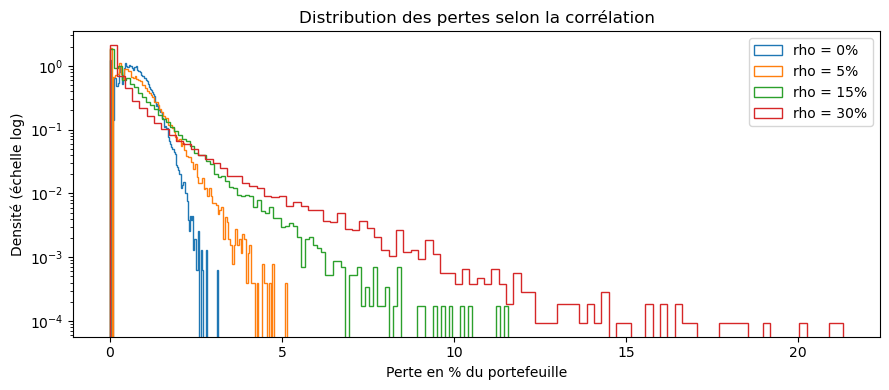

,rho,EL (%),"VaR 99,9 % (%)","ES 99,9 % (%)",Perte max (%)
0,0.00,0.72,2.25,2.44,3.13
1,0.05,0.72,3.63,3.99,5.13
2,0.15,0.72,6.46,7.78,11.57
3,0.30,0.72,11.46,14.41,21.31


In [90]:
resultats = []
fig, ax = plt.subplots(figsize=(9, 4))

for rho in [0, 0.05, 0.15, 0.30]:
    L = simuler_pertes(Port, rho)
    v = np.quantile(L, 0.999)
    resultats.append({"rho": rho,
                      "EL (%)": L.mean(),
                      "VaR 99,9 % (%)": v,
                      "ES 99,9 % (%)": L[L >= v].mean(),
                      "Perte max (%)": L.max()})
    ax.hist(L, bins=100, density=True, histtype="step", label=f"rho = {rho:.0%}")

ax.set_yscale("log")
ax.set_title("Distribution des pertes selon la corrélation")
ax.set_xlabel("Perte en % du portefeuille")
ax.set_ylabel("Densité (échelle log)")
ax.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(resultats).round(2)

la corrélation d'actifs ne change pas la perte moyenne, mais elle multiplie la VaR et l'ES. Sans corrélation, les défauts se compensent et la perte reste proche de l'EL. Avec corrélation, une récession fait défaillir beaucoup d'emprunteurs la même année. Le capital, qui couvre la queue, dépend donc surtout de la corrélation.

Partie 4 : découper les pertes en tranches

On découpe les pertes du portefeuille en trois tranches qui les absorbent dans l'ordre :
Tranche
                       Point d'attachement
                                                  Point de détachement
                                                                                     Rôle
Equity (first loss)
                              0 %
                                                         3 %
                                                                              absorbe les premières pertes
Mezzanine
                               3 %
                                                         10 %
                                                                  touchée seulement si les pertes dépassent 3 %
Senior
                               10 %
                                                         100 %
                                                                 touchée seulement si les pertes dépassent 10 %
                                                                 ### Perte d'une tranche

Une tranche $[a, d]$ commence à perdre quand la perte du portefeuille $L$ dépasse son **point d'attachement** $a$, et elle est entièrement perdue quand $L$ atteint son **point de détachement** $d$.

**Perte de la tranche, en % de sa taille :**

$$L_{[a,d]} = \frac{\min\big(\max(L - a,\ 0),\ d - a\big)}{d - a}$$

**Perte moyenne annuelle

In [91]:
tranches = {"Equity 0-3 %": (0, 3),
            "Mezzanine 3-10 %": (3, 10),
            "Senior 10-100 %": (10, 100)}

def perte_tranche(pertes, a, d):
    """Perte de la tranche [a, d] en % de sa taille, pour chaque scénario."""
    return np.clip(pertes - a, 0, d - a) / (d - a) * 100

In [92]:
#si le portefeuille perd 14 %, quelle part de la tranche 0–10 % est perdue
pert_tr=perte_tranche(14,0,10)
print ( pert_tr)

100.0


In [93]:
#si le portefeuille perd 14 %, quelle part de la tranche 10–100 % est perdue
pert_tr=perte_tranche(14,10,100)
print ( pert_tr)

4.444444444444445


Partie 5 : formule IRB, RWA et économie d'une SRT

On passe du risque au capital. La banque calcule d'abord ses RWA avec la formule de Bâle, puis évalue si une SRT libère assez de capital pour justifier son coût.

Formule IRB de Bâle (entreprises)

**Exigence de capital par euro d'exposition** (version simplifiée, sans ajustement de maturité) :

$$K = LGD \times \left[\Phi\!\left(\frac{\Phi^{-1}(PD) + \sqrt{R}\;\Phi^{-1}(0{,}999)}{\sqrt{1-R}}\right) - PD\right]$$
### RWA et capital

**RWA d'un prêt** (actifs pondérés par le risque) :

$$RWA_i = 12{,}5 \times K_i \times EAD_i$$

**RWA du portefeuille** = somme sur les $n$ prêts :

$$RWA = \sum_{i=1}^{n} 12{,}5 \times K_i \times EAD_i$$

**Pondération (densité de RWA)** :

$$RW = \frac{RWA}{EAD}$$

**Capital immobilisé** pour un ratio CET1 cible :

$$\text{Capital} = \text{ratio CET1} \times RWA$$





In [97]:
#La corrélation de Bâle, notée R, est la corrélation d’actifs que le régulateur impose dans la formule IRB. C’est l’équivalent réglementaire de ton ρ : la part de la santé de chaque entreprise qui dépend de l’économie commune.
def correlation_bale(pd_par_rating):
    w = (1 - np.exp(-50 * pd_par_rating)) / (1 - np.exp(-50))
    return 0.12 * w + 0.24 * (1 - w)
R=correlation_bale(Port["pd_par_rating"])  
Tableau =pd.DataFrame({"Rating":Port["Rating"],"PD":Port["pd_par_rating"],"R":R})
Tableau.head()

,Rating,PD,R
0,B,0.039,0.137073
1,BB,0.010,0.192784
2,B,0.039,0.137073
3,BB,0.010,0.192784
4,BBB,0.002,0.228580


In [106]:
seuil1 = norm.cdf(L)   #norm.cdf est la fonction de répartition de la loi normale, notée Φ
seuil2 = norm.ppf(0.999)                           # norm.ppf est l’inverse de norm.cdf, noté Φ⁻¹
seuil = norm.ppf(Port["pd_par_rating"].values)
L=(seuil+(np.sqrt(R))*seuil2)/np.sqrt(1-R)
Port["K"]=Port["LGD"]*(seuil1-Port["pd_par_rating"])  # CAPITAL REGLEMENATIRE A BLOQUER 
Port["RWA"]=Port["K"]*12.5*Port["EAD"]   #COMBINE DE RISQUE LA BANQUE PORTE VRAIMENT en MILLION D euro comme EAD
Port

,Rating,pd_par_rating,EAD,LGD,EL,K,RWA
0,B,0.039,12.774048,0.45,0.224185,0.096225,15.364766
1,BB,0.010,14.718264,0.45,0.066232,0.058623,10.785306
2,B,0.039,10.007412,0.45,0.175630,0.096225,12.037025
3,BB,0.010,6.438975,0.45,0.028975,0.058623,4.718377
4,BBB,0.002,5.139363,0.45,0.004625,0.024020,1.543121
...,...,...,...,...,...,...,...
195,BBB,0.002,9.543180,0.45,0.008589,0.024020,2.865390
196,BB,0.010,13.253995,0.45,0.059643,0.058623,9.712313
197,B,0.039,7.953590,0.45,0.139586,0.096225,9.566666
198,BBB,0.002,9.585481,0.45,0.008627,0.024020,2.878091


In [115]:
RWA_avant =Port["RWA"].sum()
print ( RWA_avant ) 
print(f"Les RWA du portefeuille sont de {RWA_avant:,.0f} M€, soit {RWA_avant / EAD_Total:.0%} de l'exposition")

1478.0030094562594
Les RWA du portefeuille sont de 1,478 M€, soit 74% de l'exposition


 L'économie d'une SRT : La banque achète une protection sur la tranche 0–10 % (equity et mezzanine) et garde la senior 10–100 %. Les prêts restent au bilan : seul le risque est transféré.

In [125]:
ratio_CET1 = 0.12   # capital à bloquer 
detach = 10         # la protection couvre les pertes de 0 à 10 %
coupon = 0.11          # prime annuelle payée à l'investisseur
pond_senior = 0.20     # pondération simplifiée de la senior conservée

Capital_avant = ratio_CET1*RWA_avant
Tranche_protégée=(detach/100)*EAD_Total
senior=EAD_Total-Tranche_protégée
Capital_après=ratio_CET1*senior*pond_senior
Capital_libéré=Capital_avant-Capital_après

EL = simuler_pertes(Port, 0.15)
EL_transferee = (perte_tranche(EL, 0, detach).mean() / 100) * Tranche_protégée
cout_brut = coupon * Tranche_protégée                   #cout brut du capital
cout_net= cout_brut_du_capital - EL_transferee           #cout net du cpaital

print(f"Capital avant : {Capital_avant:.0f} M€ | après : {Capital_après:.0f} M€ | libéré : {Capital_libéré:.0f} M€")
print(f"Coût brut : {cout_brut:.1f} M€/an | EL transférée : {EL_transferee:.1f} M€/an | coût net : {cout_net:.1f} M€/an")
print(f"Coût net / capital libéré : {cout_net / Capital_libéré:.1%}")


Capital avant : 177 M€ | après : 43 M€ | libéré : 134 M€
Coût brut : 22.0 M€/an | EL transférée : 14.4 M€/an | coût net : 7.6 M€/an
Coût net / capital libéré : 5.7%


Une SRT a du sens si son coût net, rapporté au capital libéré, est inférieur au coût des fonds propres. » La banque garde les prêts et la relation client, transfère le risque de première perte et réutilise le capital libéré pour de nouveaux prêts.